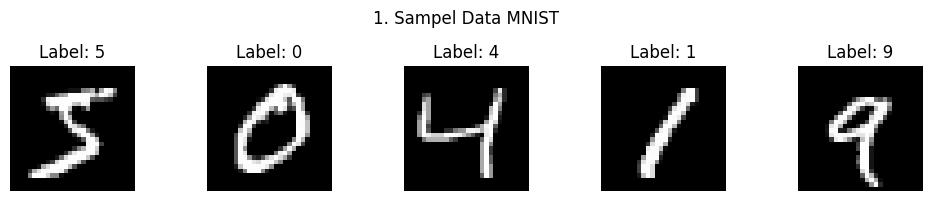

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 46ms/step - accuracy: 0.9457 - loss: 0.1823 - val_accuracy: 0.9850 - val_loss: 0.0551
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 39s 46ms/step - accuracy: 0.9836 - loss: 0.0537 - val_accuracy: 0.9885 - val_loss: 0.0393
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 40s 45ms/step - accuracy: 0.9878 - loss: 0.0382 - val_accuracy: 0.9872 - val_loss: 0.0377
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 38s 46ms/step - accuracy: 0.9908 - loss: 0.0287 - val_accuracy: 0.9897 - val_loss: 0.0351
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 46ms/step - accuracy: 0.9928 - loss: 0.0219 - val_accuracy: 0.9892 - val_loss: 0.0396


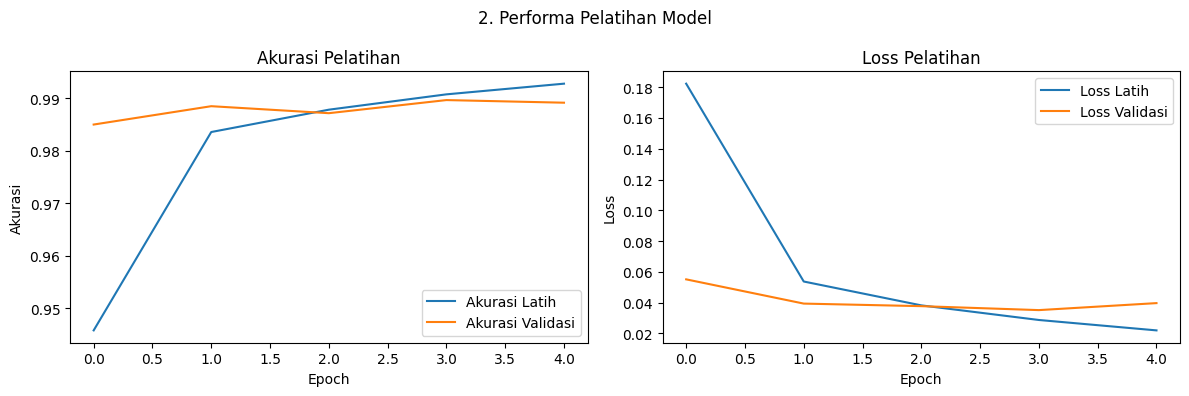

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step


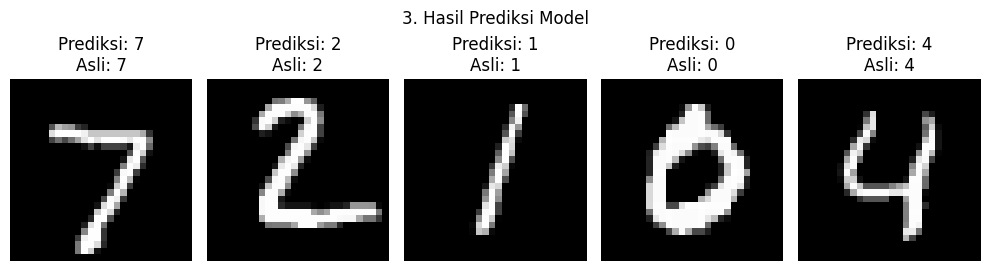

In [2]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

# Memuat dataset MNIST
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Visualisasi 5 sampel data asli sebelum normalisasi
plt.figure(figsize=(10, 2))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.suptitle("1. Sampel Data MNIST")
plt.tight_layout()
plt.show()

# Normalisasi piksel ke rentang 0 hingga 1
X_train_norm = X_train.reshape((-1, 28, 28, 1)).astype("float32") / 255.0
X_test_norm = X_test.reshape((-1, 28, 28, 1)).astype("float32") / 255.0

# Membangun arsitektur CNN
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Pelatihan model dan menyimpan riwayat
history = model.fit(X_train_norm, y_train, epochs=5, batch_size=64, validation_split=0.1)

# Visualisasi grafik Akurasi dan Loss selama pelatihan
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Akurasi Latih')
plt.plot(history.history['val_accuracy'], label='Akurasi Validasi')
plt.title('Akurasi Pelatihan')
plt.xlabel('Epoch')
plt.ylabel('Akurasi')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Loss Latih')
plt.plot(history.history['val_loss'], label='Loss Validasi')
plt.title('Loss Pelatihan')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.suptitle("2. Performa Pelatihan Model")
plt.tight_layout()
plt.show()

# Visualisasi hasil prediksi pada data uji
predictions = model.predict(X_test_norm[:5])

plt.figure(figsize=(10, 3))
for i in range(5):
    pred_label = predictions[i].argmax()
    true_label = y_test[i]
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[i], cmap='gray')
    plt.title(f"Prediksi: {pred_label}\nAsli: {true_label}")
    plt.axis('off')
plt.suptitle("3. Hasil Prediksi Model")
plt.tight_layout()
plt.show()